In [1]:
import os
import tensorflow as tf
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from tensorflow.keras import layers, models
from keras.models import Sequential, Model
from loss import custom_loss
from keras.losses import MeanSquaredError
from keras.layers import *
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

import DAE_DataGenerator
import importlib

importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_DG
#from dataprep import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator as NewDG
from loss import *
import models
importlib.reload(models)
from models import *
from dataset_utils import add_noise, quantize_manual

import matplotlib.pyplot as plt
pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-09-14 13:56:10.842451: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import models
importlib.reload(models)
from models import CreateAutoEncoder
from SoftQuantizeLayer import SoftQuantizeLayer
from AnnealingScheduler import AnnealingScheduler

def encoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = QSeparableConv2D(
        n_filters, kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = QConv2D(
        n_filters,kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    return var

def decoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = Conv2DTranspose(
        n_filters, 1, padding = 'same', strides = pool_size,
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Conv2DTranspose(
        n_filters, kernel_size,
        strides = pool_size,
        padding="same",
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)    
    var = Conv2D(shape[-1], (pool_size, pool_size), padding="same")(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    # if input_quant is not None:
    #     # quantize = lambda x: quantize_manual(x, charge_levels = input_quant, quant_values =[0,1,2,3])
    #     quantize = lambda x: hard_quantize(x, levels = [0.0,1.0,2.0,3.0], thresholds = input_quant)
    #     var = Lambda(function=quantize, dtype=tf.float32)(var)
    return var

def Qdecoder_network(shape, var, Out_bits = 2,  kernel_size=3, n_filters=5, pool_size=2):
    var = Conv2DTranspose(
        n_filters, 1, padding = 'same', strides = pool_size,
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Conv2DTranspose(
        n_filters, kernel_size,
        strides = pool_size,
        padding="same",
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)    
    var = Conv2D(shape[-1], (pool_size, pool_size), padding="same")(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Flatten()(var)
    var = Dense(math.prod(shape)*(2**Out_bits), activation='softmax')(var)
    var = Reshape((*shape, 2**Out_bits))(var)
    return var

def get_min_max(training_generator, validation_generator, logrange=True):
    if logrange:
        tmax,tmin = [training_generator.dataset_logmax, training_generator.dataset_logmin]
        vmax,vmin = [validation_generator.dataset_logmax, validation_generator.dataset_logmin]
    else:
        tmax,tmin = [training_generator.dataset_max, training_generator.dataset_min]
        vmax,vmin = [validation_generator.dataset_max, validation_generator.dataset_min]
    return np.float32(min(tmin, vmin)), np.float32(max(tmax, vmax))

def CreateSQAutoEncoder(shape, FEBits = 2, OutBits = 3, n_filters=5, pool_size=2, 
                        conv_kernel_size=3, decoder_filters = 5, mean_filter=False, 
                        thresh = False, xrange = [-1,1], log_standardize=True):
    x_base = x_in = Input(shape)
    x_base = SoftQuantizeLayer(
        n_bits=FEBits,
        initial_thresholds = (np.arange(2**FEBits - 1)+1)*100,
        # initial_thresholds = [0,240, 400],

        # initial_levels = [0.0, 0.33333, 0.66667, 1.0],
        initial_levels = np.arange(2**FEBits),
        threshold_offset = 0,
        # initial_range=[-1.0, 1.0],
        trainable_levels=False,
        trainable_thresholds=True,
        initial_k=1.0,
        trainable_k=False,
        name='soft_quantizer_output'
    )(x_base)
    stack = encoder_network(shape, x_base, n_filters=n_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    stack = Qdecoder_network(shape, stack, Out_bits = OutBits, n_filters=decoder_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    # print(type(stack))
    if xrange is not None:
        def scaled_function(data):
            return asymmetric_scaling(data, pos_scale=xrange[1], neg_scale=abs(xrange[0]))
        stack = Lambda(function = scaled_function)(stack)
    model = Model(inputs=x_in, outputs=stack)
    return model

ImportError: cannot import name 'CreateAutoEncoder' from 'models' (/home/bweiss/smart-pix/DAE/models.py)

In [20]:
'''SOURCE WEIGHTS, DATASET, INITIAL PARAMS'''
FE_bits = 2
Out_bits = 2
ThLow =  [0,30,845]# [0, 7, 23, 134, 404, 867, 1748] #[0,30,856]
ThNom = [231, 637, 1592] #[197, 289, 499, 812, 1234, 1805, 2587] #[231, 637, 1592] #


# weights_path = './SQ_DAE/model-5d8a15ee-SQDAE_Categorical_v2_2bit_80eN_Target_0_30_856-checkpoints/'
# weights_path = './SQ_DAE/model-966a30e9-SQDAE_Categorical_2bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints'
# weights_path = './SQ_DAE/model-c355fe4b-SQDAE_Categorical_3bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints/'
# weights_path = './SQ_DAE/model-9038a7c9-SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_856-checkpoints/'
# weights_path = './SQ_DAE/model-09df4cfa-SQDAE_SlimMLP_Categorical_2bit_80eN_Target_0_30_845_TEST-checkpoints/'
weights_path = './/SQ_DAE/model-bb57b09d-SQDAE_SlimTransformer_Categorical_2bit_80eN_Target_0_30_845_TEST-checkpoints/'
# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_80eN_catgoricalOut_Target_0_30_856"
# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_80eN_catgoricalOut_Target_0_7_23_134_404_867_1748"
# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_856"
tfrecords_dir_val= "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_845"

In [21]:
'''reconstruct the SQuautoencoder from weights'''
import models
import loss
importlib.reload(models)
importlib.reload(loss)
from loss import *
from models import *
from SoftQuantizeLayer import SoftQuantizeLayer
from AnnealingScheduler import AnnealingScheduler
import math

# weights_path = './SQ_DAE/model-e12251df-SQDAE_2bit_80eN_SSIM_LogScaled_QRange0to3_80eThreshOffset-checkpoints/'
# weights_path = './SQ_DAE/model-6a94c6f9-SQDAE_2bit_80eN_CategoricalOutput_transformerTarget-checkpoints/'
# weights_path = './SQ_DAE/model-11644ab3-SQDAE_2bit_80eN_CategoricalOutput_lowThreshTarget-checkpoints/'
# weights_path = './SQ_DAE/model-5d8a15ee-SQDAE_Categorical_v2_2bit_80eN_Target_0_30_856-checkpoints/'
# weights_path = './SQ_DAE/model-966a30e9-SQDAE_Categorical_2bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints'
# weights_path = './SQ_DAE_regression/model-7f27e133-SQDAE_regression_CategoricalLowThreshTarget-checkpoints/'

base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")

Loading model from .//SQ_DAE/model-bb57b09d-SQDAE_SlimTransformer_Categorical_2bit_80eN_Target_0_30_845_TEST-checkpoints/weights.754-t95021.8672-v101612.5859.hdf5


In [ ]:
'''Load SQ DAE from weights'''
model=CreateSQAutoEncoder((16,16,2), FEBits = FE_bits, OutBits = Out_bits, n_filters=5, pool_size=2, conv_kernel_size = 3, 
                        decoder_filters = 128, 
                        # input_quant = [0.2,0.6,3.0],
                        xrange = None
                       )
model.load_weights(latest_checkpoint)

In [22]:
'''Load SQ DAE Transofrmer from weights'''
model = Create_SQDAE_transformer_model(input_shape=(16,16,2),   
                             patch_size=(3,4),        
                             embed_dim=64,           
                             num_heads=4,            
                             ff_dim=128,              
                             num_layers=4,            
                             dropout=0.1,        
                             threshold_offset=0,
                             n_bits=2,
                             initial_thresholds=initial_thresholds,
                             final_outputs=14         
                            )
model.load_weights(latest_checkpoint)

In [12]:
'''Load SQAutoencoder_conv2D from weights'''
initial_thresholds = [1, 30, 845]
model = CreateSQAutoEncoder_MLPSlim(shape = (16,16,2), 
                          # n_filters=128,
                          # pool_size=3,
                          initial_thresholds=initial_thresholds)

model.load_weights(latest_checkpoint)

2026-09-02 17:37:36.226888: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-09-02 17:37:37.184541: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-09-02 17:37:37.185054: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-09-02 17:37:37.186411: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

In [13]:
'''Load data for DAE training'''
# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_80eN_catgoricalOut"
# tfrecords_dir_train = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_80eN_catgoricalOut"

# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_80eN_catgoricalOut_Target_0_30_856"
# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_80eN_catgoricalOut_Target_0_7_23_134_404_867_1748"
# tfrecords_dir_train = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_80eN_catgoricalOut_lowThreshTarget"

validation_generator = DAE_DG(
    load_from_tfrecords_dir = tfrecords_dir_val,
)
# training_generator = DAE_DG(
#     load_from_tfrecords_dir = tfrecords_dir_train,
# )



Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_845/metadata.json


In [23]:
import math
###COMPUTE TRUE FRACTION OF PIXELS IN EACH CLASS
cshape = (16,16,2)
npixels = cshape[0]*cshape[1]
sumax = (1,2,3)
N_all = pd.DataFrame()
for i in tqdm(range(len(validation_generator))):
    true_clusters = np.argmax(validation_generator[i][1][:][:,:,:],axis = -1)
    N= pd.DataFrame()
    levels = np.arange(np.max(true_clusters)+1)
    for l in levels:
        true_catmask = true_clusters == l
        npix_perlevel = np.sum(true_catmask, axis = sumax) 
        N[str(l)] = npix_perlevel
        # N[f'{l}_tot'] = math.prod(true_clusters.shape)
    N_all = pd.concat([N_all, N], ignore_index=True)

for i in range(4):
    tot = np.sum(N_all[str(i)])
    print(f'frac of pix = {i} is:', tot/(512*len(N_all)))

100%|██████████| 21/21 [00:02<00:00,  9.49it/s]

frac of pix = 0 is: 0.9015512271593284
frac of pix = 1 is: 0.024292990460377396
frac of pix = 2 is: 0.05085206270408507
frac of pix = 3 is: 0.0233037196762091


(-11.779398424427853, 16.239131633988272)
(5000, 16, 16, 2, 8) float32


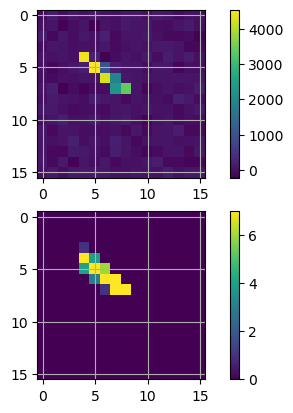

In [70]:
fig, ax = plt.subplots(2,1)
batch_index = 0
N = 42
ts = 1

X_in = validation_generator[batch_index][0][N]
X_out = validation_generator[batch_index][1][N]

def get_min_max(training_generator, validation_generator):
    tmax,tmin = [training_generator.dataset_max, training_generator.dataset_min]
    vmax,vmin = [validation_generator.dataset_max, validation_generator.dataset_min]
    return min(tmin, vmin), max(tmax, vmax)

print(get_min_max(validation_generator, validation_generator))
print(validation_generator[batch_index][1].shape, validation_generator[batch_index][1][N].dtype)

a = ax[0].imshow(X_in[:,:,ts]) 
fig.colorbar(a)
a = ax[1].imshow(np.argmax(X_out[:,:,ts,], axis = -1)) 
# ax[2].imshow((X_in-X_out)[:,:,ts]) 
#indicies: batch_index, in/out, index_in_batch, {nxm pixels}, time slice

fig.colorbar(a)

In [15]:
import warnings
warnings.filterwarnings("ignore")

def PCatAccuarcyByLevel(X_val, model = None, QThresh = None):
    cshape = (16,16,2)
    npixels = cshape[0]*cshape[1]
    
    acc_all = pd.DataFrame()

    desc_string = "supplied model" if model is not None else f'HQ Ths: [{QThresh}]'
    for i in tqdm(range(len(X_val)), desc = f'Computing accuracy with {desc_string}'):
        true_clusters = np.argmax(X_val[i][1][:][:,:,:],axis = -1)
        test_clusters = X_val[i][0][:][:,:,:].numpy()
        
        if model is not None:
            p_out = np.argmax(model.predict(test_clusters,  verbose = 0), axis=-1)
            sumax = (1,2,3)
        elif QThresh is not None:
            true_clusters = true_clusters.reshape(true_clusters.shape[0], math.prod(cshape))
            test_clusters = test_clusters.reshape(true_clusters.shape[0], math.prod(cshape))
            p_out = quantize_manual(test_clusters, charge_levels = QThresh, quant_values=np.arange(len(QThresh)+1) )
            sumax = 1
            # print(p_out.shape, true_clusters.shape)
        acc= pd.DataFrame()
        levels = np.arange(np.max(true_clusters)+1)
        for l in levels:
            true_catmask = true_clusters == l
            pred_catmask = p_out == l
            
            npix_perlevel = np.sum(true_catmask, axis = sumax) 
            correct_preds = np.sum((true_catmask & pred_catmask), axis = sumax) 
            # print("npix and correct preds shape: ", npix_perlevel.shape, correct_preds.shape)
            acc[str(l)] = correct_preds/npix_perlevel
            # print(acc.shape)
        acc_all = pd.concat([acc_all, acc])
        
    return acc_all

def PCatAccuarcyByTS(X_val, model = None, QThresh = None):
    cshape = (16,16,2)
    npixels = cshape[0]*cshape[1]
    
    ts0acc = np.array([])
    ts19acc = np.array([])
        
    for i in tqdm(range(len(validation_generator)), desc = 'Computing accuracy with supplied model'):
        true_clusters = np.argmax(X_val[i][1][:][:,:,:,:],axis = -1)
        test_clusters = X_val[i][0][:][:,:,:]
        
        if model is not None:
            p_out = np.argmax(model.predict(test_clusters,  verbose = 0), axis=-1)
            ts0acc = np.append(ts0acc,(npixels - np.count_nonzero(p_out[:,:,:,0]-true_clusters[:,:,:,0],  axis = (1,2)))/npixels)
            ts19acc = np.append(ts19acc,(npixels - np.count_nonzero(p_out[:,:,:,1]-true_clusters[:,:,:,1],  axis = (1,2)))/npixels)

        elif QThresh is not None:
            true_clusters_TS0 = true_clusters[:,:,:,0]
            test_clusters_TS0 = test_clusters[:,:,:,0].numpy()
            true_clusters_TS19 = true_clusters[:,:,:,-1]
            test_clusters_TS19 = test_clusters[:,:,:,-1].numpy()
    
            true_clusters_TS0 = true_clusters_TS0.reshape(true_clusters_TS0.shape[0], npixels)
            true_clusters_TS19 = true_clusters_TS19.reshape(true_clusters_TS19.shape[0], npixels)
            test_clusters_TS0 = test_clusters_TS0.reshape(true_clusters_TS0.shape[0], npixels)
            test_clusters_TS19 = test_clusters_TS19.reshape(true_clusters_TS19.shape[0], npixels)
            
            p_out_TS0 = quantize_manual(test_clusters_TS0, charge_levels = QThresh, quant_values=[0,1,2,3])
            p_out_TS19 = quantize_manual(test_clusters_TS19, charge_levels = QThresh, quant_values=[0,1,2,3])
            ts0acc = np.append(ts0acc,(npixels - np.count_nonzero(p_out_TS0-true_clusters_TS0,  axis = 1))/npixels)
            ts19acc = np.append(ts19acc,(npixels - np.count_nonzero(p_out_TS19-true_clusters_TS19,  axis = 1))/npixels)
    return ts0acc, ts19acc

In [24]:
# ThLow = [0, 7, 23, 134, 404, 867, 1748] #[0,30,856]
# ThNom = [197, 289, 499, 812, 1234, 1805, 2587] #[231, 637, 1592]
DAEacc_all = PCatAccuarcyByLevel(validation_generator, model = model)
# LowThreshacc_all = PCatAccuarcyByLevel(validation_generator, QThresh = ThLow#[0,30,856]
#                                       )
# NomThreshacc_all = PCatAccuarcyByLevel(validation_generator, QThresh = ThNom#[231, 637, 1592]
#                                       )



Computing accuracy with supplied model: 100%|██████████| 21/21 [00:27<00:00,  1.32s/it]


In [25]:
DAEacc_all.to_parquet(f'2bit_Transformer_DAE_target{ThLow}.parquet')
# NomThreshacc_all.to_parquet(f'HQNominal_target{ThLow}.parquet')
# LowThreshacc_all.to_parquet(f'HQIdeal_target{ThLow}.parquet')

print(DAEacc_all)
for i in range(4):
    acc_tot = np.mean(DAEacc_all[str(i)])
    print(acc_tot)

             0         1         2         3
0     1.000000  0.900000  0.894737  1.000000
1     0.983945  0.666667  0.844444  1.000000
2     0.997840  0.777778  0.916667  1.000000
3     0.993182  0.545455  0.928571  0.947368
4     1.000000  0.900000  1.000000  1.000000
...        ...       ...       ...       ...
4995  0.995546  0.583333  0.970588  0.941176
4996  0.997773  0.428571  0.904762  0.928571
4997  0.993435  0.764706  0.964286  1.000000
4998  1.000000  0.800000  1.000000  0.916667
4999  0.995951  0.000000  0.750000  1.000000

[103817 rows x 4 columns]
0.9964069881901272
0.701580674243832
0.904978921730121
0.9712657204051581


(104453, 4)
          0         1         2         3
0  0.993562  0.375000  0.840000  1.000000
1  0.980132  0.500000  0.838710  1.000000
2  1.000000  0.684211  0.842105  0.933333
3  1.000000  0.769231  0.736842  1.000000
4  0.995444  0.700000  0.945946  0.812500


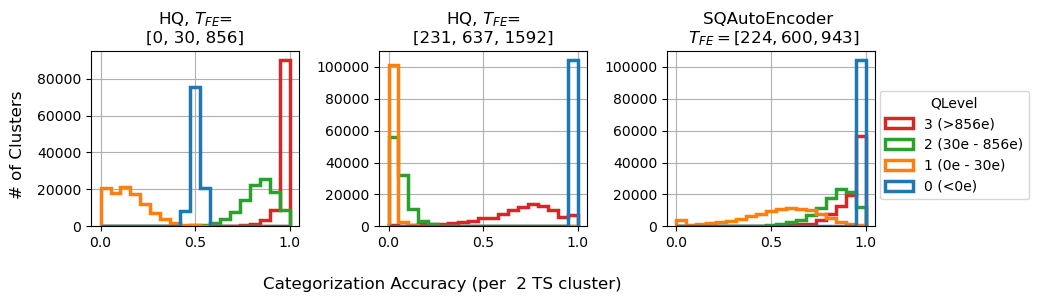

In [122]:
nbins = 20
thI = [0,4] #[4,7]
fig, ax = plt.subplots(1,3, figsize = (9,3))
plt.rcParams['axes.grid'] = True
def get_bins(acc_arr, nbins):
    globalmin = min(acc_arr.min().min(), acc_arr.min().min())
    bins = np.linspace(globalmin, 1, nbins)
    return bins

print(DAEacc_all.shape)
print(DAEacc_all.head())

# LowThreshacc_all = PCatAccuarcyByLevel(validation_generator, QThresh = [0,240,1600])

ax[0].hist(LowThreshacc_all, bins = get_bins(LowThreshacc_all, nbins = nbins), stacked = False, histtype='step', linewidth=2.5)
ax[0].set_title("HQ, $T_{FE}$="+f"\n{ThLow}")

# NomThreshacc_all = PCatAccuarcyByLevel(validation_generator, QThresh = [300, 650, 1600])

ax[1].hist(NomThreshacc_all, bins = get_bins(NomThreshacc_all, nbins = nbins), stacked = False, histtype='step', linewidth=2.5)
ax[1].set_title("HQ, $T_{FE}$="+f"\n{ThNom}")

ax[2].hist(DAEacc_all, bins = get_bins(DAEacc_all, nbins = nbins), stacked = False, histtype='step', linewidth=2.5)
ax[2].set_title("SQAutoEncoder \n $T_{FE}=[224, 600, 943]$")
# ax[2].set_title("SQAutoEncoder \n $T_{FE}=[282, 504, 1656]$")

fig.supylabel("# of Clusters")
fig.supxlabel("Categorization Accuracy (per  2 TS cluster)")
fig.legend(['3 (>856e)','2 (30e - 856e)','1 (0e - 30e)','0 (<0e)'], loc = 'center right', bbox_to_anchor = [1.16, 0.5], title = "QLevel")
# fig.legend(['7','6','5','4','3','2','1','0'], loc = 'center right', bbox_to_anchor = [1.16, 0.5], title = "QLevel")

fig.tight_layout()

fig.savefig("CatAccuracy_byLevel_2bit_Target_0_30_856", bbox_inches='tight')

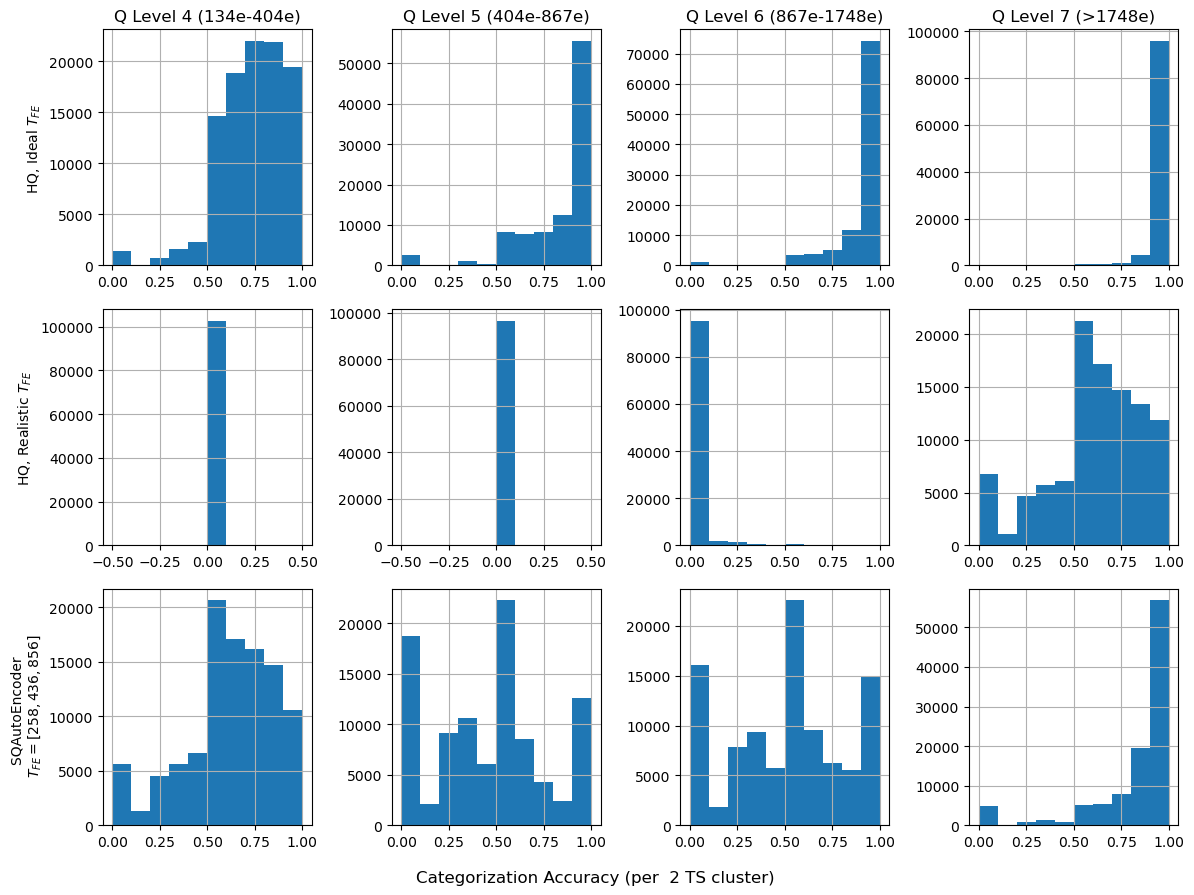

In [38]:
nbins = 10
fig, ax = plt.subplots(3,4, figsize = (12,9))
plt.rcParams['axes.grid'] = True
def get_bins(acc_arr, nbins):
    globalmin = min(acc_arr.min().min(), acc_arr.min().min())
    bins = np.linspace(globalmin, 1, nbins)
    return bins

# print(LowThreshacc_all['0'].shape)
# print(DAEacc_all.head())

for i in range(4):
    j= i+4
    if j == 0:
        ax[0][i].set_title(f"Q Level {j} (<{ThLow[j]}e)")
    elif j == 7:
        ax[0][i].set_title(f"Q Level {j} (>{ThLow[-1]}e)")
    else:
        ax[0][i].set_title(f"Q Level {j} ({ThLow[j-1]}e-{ThLow[j]}e)")
    ax[0][i].hist(LowThreshacc_all[f'{j}'], #bins = get_bins(LowThreshacc_all, nbins = nbins), 
                  # stacked = False, histtype='step', 
                  linewidth=2.5)
        
    ax[1][i].hist(NomThreshacc_all[f'{j}'], #bins = get_bins(NomThreshacc_all, nbins = nbins), 
                  # stacked = False, histtype='step', 
                  linewidth=2.5)
    
    ax[2][i].hist(DAEacc_all[f'{j}'], #bins = get_bins(DAEacc_all, nbins = nbins), 
                  # stacked = False, histtype='step', 
                  linewidth=2.5)

ax[0][0].set_ylabel("HQ, Ideal $T_{FE}$")
ax[1][0].set_ylabel("HQ, Realistic $T_{FE}$")
# ax[2][0].set_ylabel("SQAutoEncoder \n $T_{FE}=[224, 600, 943]$") #2x2
ax[2][0].set_ylabel("SQAutoEncoder \n $T_{FE}=[258, 436, 856]$") #2x3
# ax[2][0].set_ylabel("SQAutoEncoder \n $T_{FE}=[0,240, 360, 447, 653, 921, 1368]$") #3x3



# fig.supylabel("# of Clusters")
fig.supxlabel("Categorization Accuracy (per  2 TS cluster)")
# fig.legend(['3 (>856e)','2 (30e - 856e)','1 (0e - 30e)','0 (<0e)'], loc = 'center right', bbox_to_anchor = [1.16, 0.5], title = "QLevel")
# fig.legend(['7','6','5','4','3','2','1','0'], loc = 'center right', bbox_to_anchor = [1.16, 0.5], title = "QLevel")

fig.tight_layout()

fig.savefig(f"CatAccuracy_byLevelUnstacked2_2bit_Target_{ThLow}.png", bbox_inches='tight')

In [79]:
ts0_DAEacc, ts19_DAEacc= PCatAccuarcyByTS(validation_generator, model = model)

# ts0_LowThreshacc, ts19_LowThreshacc= PCatAccuarcyByTS(validation_generator, QThresh = T)
# ts0_NomThreshacc, ts19_NomThreshacc= PCatAccuarcyByTS(validation_generator, QThresh = [231, 637, 1592])

Computing accuracy with supplied model: 100%|██████████| 21/21 [00:18<00:00,  1.17it/s]


In [22]:
print(ts0_DAEacc, ts19_DAEacc)
print(ts0_LowThreshacc, ts19_LowThreshacc)


NameError: name 'ts0_DAEacc' is not defined

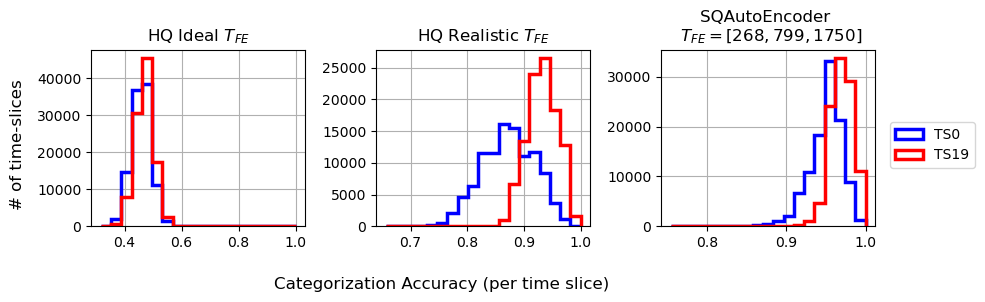

In [80]:
fig, ax = plt.subplots(1,3, figsize = (9,3))
plt.rcParams['axes.grid'] = True
def get_bins(acc_arr, nbins):
    globalmin = min(acc_arr.min().min(), acc_arr.min().min())
    bins = np.linspace(globalmin, 1, nbins)
    return bins

def get_binsTS(ts0acc, ts19acc, nbins):
    globalmin = min(min(ts0acc), min(ts19acc))
    bins = np.linspace(globalmin, 1, nbins)
    return bins

ax[0].hist(ts0_LowThreshacc, histtype = 'step', bins = get_binsTS(ts0_LowThreshacc,ts19_LowThreshacc,20), color = 'blue', linewidth=2.5)
ax[0].hist(ts19_LowThreshacc, histtype = 'step', bins = get_binsTS(ts0_LowThreshacc,ts19_LowThreshacc,20), color = 'red', linewidth=2.5)
ax[0].set_title("HQ Ideal $T_{FE}$")

ax[1].hist(ts0_NomThreshacc, histtype = 'step', bins = get_binsTS(ts0_NomThreshacc,ts19_NomThreshacc,20), color = 'blue', linewidth=2.5)
ax[1].hist(ts19_NomThreshacc, histtype = 'step', bins = get_binsTS(ts0_NomThreshacc,ts19_NomThreshacc,20), color = 'red', linewidth=2.5)
ax[1].set_title("HQ Realistic $T_{FE}$")
# ax[1].set_title("Qth=[231, 637, 1592]")

ax[2].hist(ts0_DAEacc, histtype = 'step', bins = get_binsTS(ts0_DAEacc,ts19_DAEacc,20), color = 'blue', linewidth=2.5)
ax[2].hist(ts19_DAEacc, histtype = 'step', bins = get_binsTS(ts0_DAEacc,ts19_DAEacc,20), color = 'red', linewidth=2.5)
ax[2].set_title("SQAutoEncoder \n $T_{FE}=[268, 799, 1750]$")
# ax[2].set_title("SQAutoEncoder \n $T_{FE}=[0,240, 360, 447, 653, 921, 1368]$") #3x3


fig.legend(["TS0", "TS19"], loc = 'center right', bbox_to_anchor = [1.1, 0.5])
fig.supylabel("# of time-slices")
fig.supxlabel("Categorization Accuracy (per time slice)")

# print(DAEacc_all.shape)
# print(DAEacc_all.head())

# LowThreshacc_all = PCatAccuarcyByLevel(validation_generator, QThresh = [0,240,1600])

# ax[0].hist(LowThreshacc_all, bins = get_bins(LowThreshacc_all, nbins = 10), stacked = True)
# ax[0].set_title("Qth=[0, 240, 1600]")

# NomThreshacc_all = PCatAccuarcyByLevel(validation_generator, QThresh = [300, 650, 1600])

# ax[1].hist(NomThreshacc_all, bins = get_bins(NomThreshacc_all, nbins = 10), stacked = True)
# ax[1].set_title("Qth=[300, 650, 1600]")

# ax[2].hist(DAEacc_all, bins = get_bins(DAEacc_all, nbins = 10), stacked = True)
# ax[2].set_title("DAE, low Thresh Target")

# fig.legend(['0','1','2','3'], loc = 'center right', bbox_to_anchor = [1.1, 0.5], title = "QLevel")
fig.tight_layout()
fig.savefig("CatAccuracy_byTS_2bit_Target_0_7_23_134_404_867_1748", bbox_inches='tight')


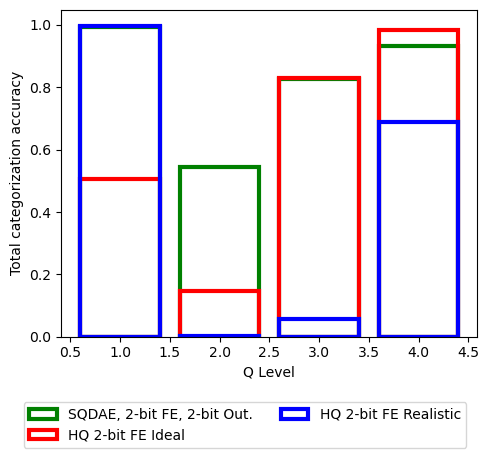

In [3]:
# files = ['2bit_DAE_target[0, 7, 23, 134, 404, 867, 1748].parquet', 
#  '3bit_DAE_target[0, 7, 23, 134, 404, 867, 1748].parquet',
#  'HQIdeal_target[0, 7, 23, 134, 404, 867, 1748].parquet',
#  'HQNominal_target[0, 7, 23, 134, 404, 867, 1748].parquet'
# ]

files = [
    '2bit_DAE_target[0, 30, 856].parquet',
    'HQIdeal_target[0, 30, 856].parquet',
    'HQNominal_target[0, 30, 856].parquet'
]

labels = ['SQDAE, 2-bit FE, 2-bit Out.',
          # 'SQDAE, 3-bit FE, 3-bit Out.',
          'HQ 2-bit FE Ideal',
          'HQ 2-bit FE Realistic',
         ]
colors = ['green', 'red', 'blue', 'black']
fig,ax = plt.subplots(1,1, figsize = (5,4))
for j, file in enumerate(files):
    df = pd.read_parquet('CatAccuracy_parquets/'+file)
    acc_tot = [np.mean(df[str(i)]) for i in range(4)]
    ax.bar(np.arange(4)+1, acc_tot, edgecolor =colors[j], linewidth= 3, facecolor='none', label = labels[j])
    # print(acc_tot)

ax.set_xlabel('Q Level')
ax.set_ylabel('Total categorization accuracy')

fig.legend(ncols = 2, loc = 'lower center', bbox_to_anchor = [0.5, -0.15])
fig.tight_layout()

# fig.savefig("CatAccuracy_total_2bit_Target_0_30_856", bbox_inches='tight')


{'SQAuto MLP': [0.9946225693698708, 0.5833520589233936, 0.8421788556566437, 0.9216305326483487], 'SQAuto Conv2D': [0.9946609156034821, 0.5430698698236804, 0.8278388398462835, 0.9332715818472069], 'SQAuto XFormer': [0.9964069881901272, 0.701580674243832, 0.904978921730121, 0.9712657204051581], 'HQ Ideal': [0.5065863725153593, 0.14752348078423774, 0.8312682407152207, 0.9844235277779626], 'HQ Realistic': [0.9980773840642125, 0.00308724838903263, 0.055716742053303736, 0.6896479189341612]}


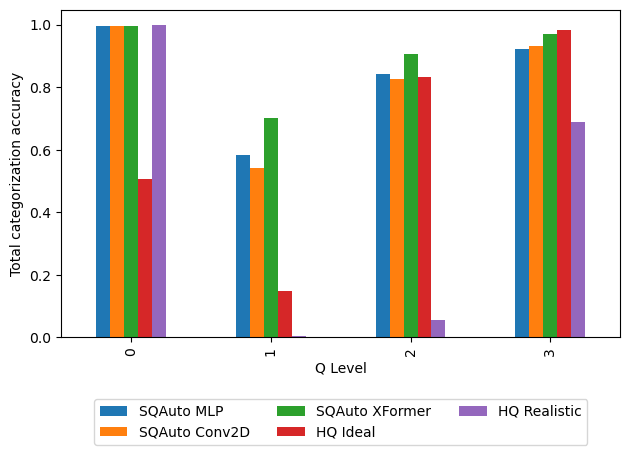

In [32]:
# files = ['2bit_DAE_target[0, 7, 23, 134, 404, 867, 1748].parquet', 
#  '3bit_DAE_target[0, 7, 23, 134, 404, 867, 1748].parquet',
#  'HQIdeal_target[0, 7, 23, 134, 404, 867, 1748].parquet',
#  'HQNominal_target[0, 7, 23, 134, 404, 867, 1748].parquet'
# ]

files = [
    '2bit_MLP_DAE_target[0, 30, 845].parquet',
    '2bit_DAE_target[0, 30, 856].parquet',
    '2bit_Transformer_DAE_target[0, 30, 845].parquet',
    'HQIdeal_target[0, 30, 856].parquet',
    'HQNominal_target[0, 30, 856].parquet'
]

labels = ['SQAuto MLP',
          'SQAuto Conv2D',
          'SQAuto XFormer',
          # 'SQDAE, 3-bit FE, 3-bit Out.',
          'HQ Ideal',
          'HQ Realistic',
         ]
colors = ['green', 'red', 'blue', 'black']
# fig,ax = plt.subplots(1,1, figsize = (5,4))
all_bars = {}
for j, file in enumerate(files):
    df = pd.read_parquet('CatAccuracy_parquets/'+file)
    acc_tot = [np.mean(df[str(i)]) for i in range(4)]
    all_bars[labels[j]] = acc_tot
print(all_bars)
all_bars = pd.DataFrame(all_bars)
all_bars.plot(kind='bar', stacked=False)
# ax.bar(all_bars, tick_labels = np.arange(4)+1,  edgecolor =colors[j], linewidth= 3, label = labels[j])


plt.xlabel('Q Level')
plt.ylabel('Total categorization accuracy')

plt.legend(ncols = 3, loc = 'lower center', bbox_to_anchor = [0.5, -0.35])
plt.tight_layout()

plt.savefig("CatAccuracy_total_allModels_Target_0_30_856", bbox_inches='tight')


In [ ]:
meta_dict = {}
meta_dict['SlimConv2D_0e'] = ''
meta_dict['SlimConv2D_40e'] = 'model-48edb3d3-SQAutoEncoder_SlimConv2D_40e_2bit-checkpoints'
meta_dict['SlimConv2D_80e'] = 'model-72936707-SQAutoEncoder_SlimConv2D_80e_2bit-checkpoints'
meta_dict['SlimConv2D_120e'] = 'model-0bfb046f-SQAutoEncoder_SlimConv2D_120e_2bit-checkpoints'
meta_dict['SlimConv2D_240e'] = 'model-3522896b-SQAutoEncoder_SlimConv2D_240e_2bit-checkpoints'